In [ ]:
"""
Análise qualitativa de erros (DBSCAN, Pick) -- figuras para o artigo.
 
Diferenças face à versão anterior deste notebook:
  - Usa o OOF_Movement guardado no .pkl do LOSO (previsões CEGAS, as mesmas que
    geraram as tabelas). Não treina nenhum modelo aqui.
  - Avaliação ao nível do movimento (sub, repID, movID), não do trial.
  - Mostra TODOS os TP, FP e FN, sobrepostos às trajetórias nominais (cinzento),
    em vez de um exemplo sorteado por categoria.
  - Tempo normalizado para [0, 1] em cada movimento, para os movimentos de
    durações diferentes ficarem comparáveis no mesmo eixo.
"""
import os
import sys
 
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
sys.path.insert(0, '../../..')  # Load Parent directory to import utils
from utils.constants import Configs
 
MODEL = "DBSCAN"
TARGET_MOVEMENT = "Pick"
OUTPUT_DIR = "images"
os.makedirs(OUTPUT_DIR, exist_ok=True)
 
SIGNALS = {
    "ShapeBased":   [("x", "X"), ("y", "Y"), ("z", "Z")],
    "FeatureBased": [("vel", "Velocity"), ("acc", "Acceleration")],
}
 
CATEGORY_STYLE = {
    "TP": dict(color="#2ca02c", title="True Positives"),
    "FP": dict(color="#d62728", title="False Positives"),
    "FN": dict(color="#ff7f0e", title="False Negatives"),
}

### Data

In [12]:
raw_df = pd.read_csv(Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR)
raw_df = raw_df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
raw_df = raw_df[raw_df['movLabel'] == TARGET_MOVEMENT].copy()
 
 
def load_oof(model, representation, movement):
    """Previsões cegas do LOSO ao nível do movimento (as que geraram as tabelas)."""
    path = Configs.loso_results_path(model, representation, movement)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Resultados LOSO não encontrados em {path}.")
    res = joblib.load(path)
    if "OOF_Movement" not in res:
        raise KeyError("O .pkl não tem 'OOF_Movement' -- foi gerado com uma versão antiga do pipeline.")
    return res["OOF_Movement"].copy()
 
 
def split_outcomes(oof):
    """Separa o OOF em TP / FP / FN / TN."""
    pred, true = oof["pred_is_outlier"] == 1, oof["true_is_outlier"] == 1
    return {
        "TP": oof[pred & true],
        "FP": oof[pred & ~true],
        "FN": oof[~pred & true],
        "TN": oof[~pred & ~true],
    }

### Verificação: as contagens têm de bater com as tabelas do artigo

In [13]:
for representation in SIGNALS:
    oof = load_oof(MODEL, representation, TARGET_MOVEMENT)
    out = split_outcomes(oof)
    n_pos = int(oof["true_is_outlier"].sum())
    print(f"[{representation}] TP={len(out['TP'])}  FP={len(out['FP'])}  FN={len(out['FN'])}  "
          f"TN={len(out['TN'])}  | positivos conhecidos={n_pos}")
 
    # Taxa de rejeição por movID: dá um número à observação sobre o movID 1
    rej_by_mov = (oof.groupby("movID")["pred_is_outlier"].mean() * 100).round(2)
    print("  Taxa de rejeição por movID (%):", rej_by_mov.to_dict())
 
# Se TP+FN != 13 (Pick) ou se as contagens divergirem das tabelas, NÃO avances:
# o .pkl em cache é de uma execução antiga.

[ShapeBased] TP=10  FP=45  FN=3  TN=322  | positivos conhecidos=13
  Taxa de rejeição por movID (%): {1: 4.21, 3: 13.68, 5: 26.32, 7: 13.68}
[FeatureBased] TP=8  FP=12  FN=5  TN=355  | positivos conhecidos=13
  Taxa de rejeição por movID (%): {1: 3.16, 3: 6.32, 5: 9.47, 7: 2.11}


### Figura: todos os erros sobrepostos às trajetórias nominais

In [14]:
def movement_series(raw_df, row, col):
    """Série temporal de um movimento, com tempo normalizado em [0, 1]."""
    m = raw_df[(raw_df["sub"] == row.sub) & (raw_df["repID"] == row.repID) &
               (raw_df["movID"] == row.movID)].sort_values("step")
    values = m[col].to_numpy()
    return np.linspace(0, 1, len(values)), values
 
 
def plot_error_overlay(raw_df, outcomes, representation, categories=("TP", "FP", "FN"),
                       max_nominal=150, save_path=None):
    """
    Uma linha por categoria (TP/FP/FN), uma coluna por sinal. Cada painel mostra as
    trajetórias nominais (TN) a cinzento como contexto, e as da categoria a cor.
    """
    signals = SIGNALS[representation]
    n_rows, n_cols = len(categories), len(signals)
    plt.rcParams.update({"font.size": 10, "font.family": "serif"})
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows),
                             dpi=300, squeeze=False, sharex=True)
 
    nominal = outcomes["TN"]
    if len(nominal) > max_nominal:  # só para o gráfico não ficar pesado
        nominal = nominal.sample(n=max_nominal, random_state=0)
 
    for r, cat in enumerate(categories):
        style = CATEGORY_STYLE[cat]
        rows = list(outcomes[cat].sort_values(["sub", "repID", "movID"]).itertuples())
        for c, (col, label) in enumerate(signals):
            ax = axes[r][c]
            for row in nominal.itertuples():
                t, v = movement_series(raw_df, row, col)
                ax.plot(t, v, color="0.8", linewidth=0.6, zorder=1)
            for row in rows:
                t, v = movement_series(raw_df, row, col)
                ax.plot(t, v, color=style["color"], linewidth=1.5, alpha=0.9, zorder=2)
            ax.grid(True, linestyle=":", alpha=0.5)
            if r == n_rows - 1:
                ax.set_xlabel("Normalized time")
            if c == 0:
                ax.set_ylabel(f"{style['title']} (n={len(rows)})\n{label}")
            else:
                ax.set_ylabel(label)
 
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
        print(f"✅ Figura guardada em {save_path}")
    plt.show()

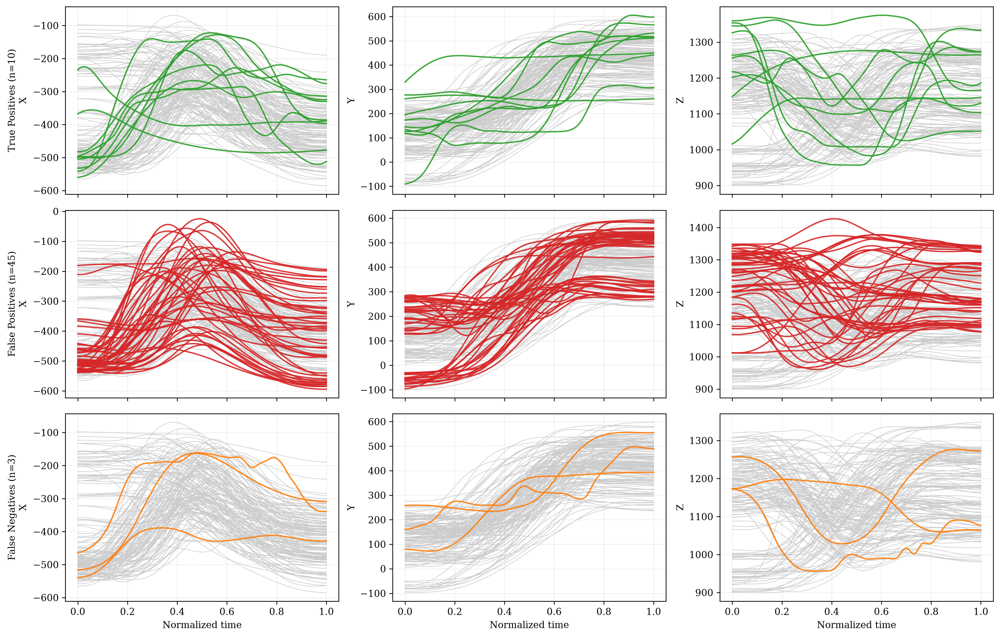

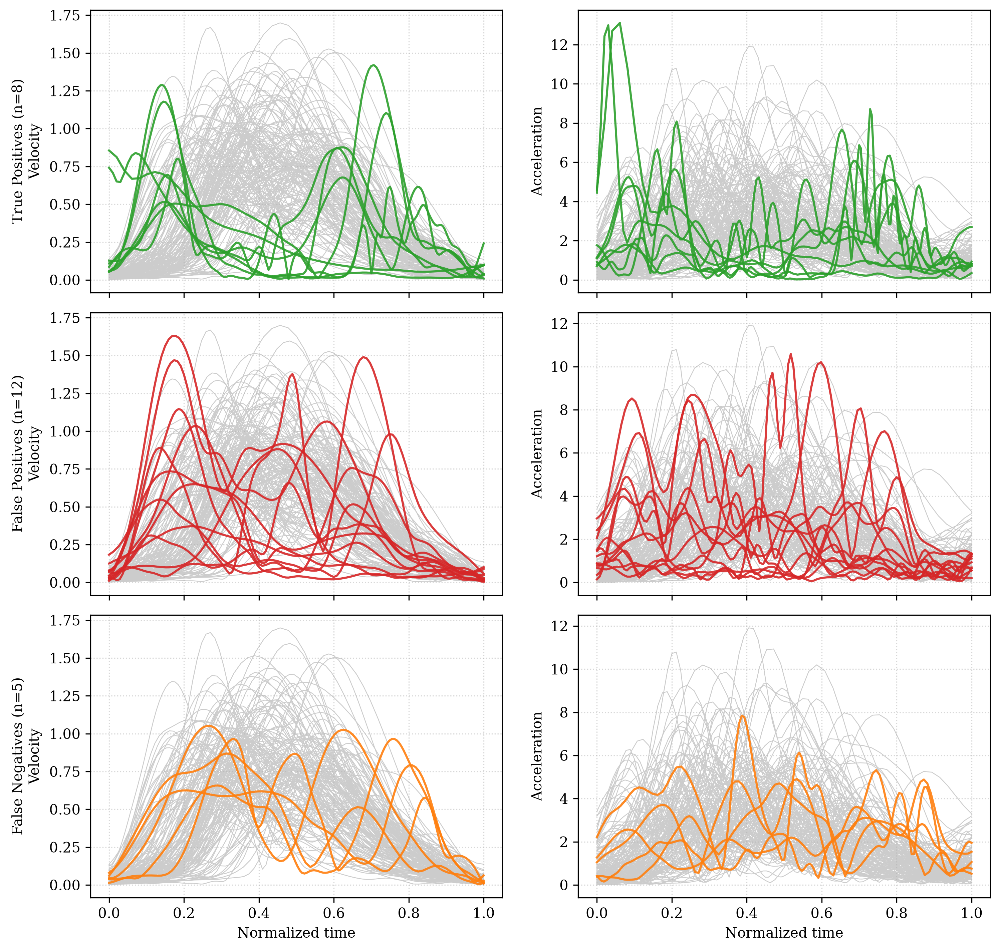

In [15]:
for representation in SIGNALS:
    oof = load_oof(MODEL, representation, TARGET_MOVEMENT)
    outcomes = split_outcomes(oof)
    plot_error_overlay(
        raw_df, outcomes, representation
    )

### Lista dos movimentos de cada categoria (material suplementar / rastreabilidade

In [16]:
rows = []
for representation in SIGNALS:
    outcomes = split_outcomes(load_oof(MODEL, representation, TARGET_MOVEMENT))
    for cat in ("TP", "FP", "FN"):
        part = outcomes[cat][["sub", "repID", "movID"]].copy()
        part.insert(0, "Category", cat)
        part.insert(0, "Representation", representation)
        rows.append(part)
 
error_list = pd.concat(rows, ignore_index=True).sort_values(
    ["Representation", "Category", "sub", "repID", "movID"])
error_list.to_csv(os.path.join(OUTPUT_DIR, f"error_list_{MODEL}_{TARGET_MOVEMENT}.csv"), index=False)
error_list

,Representation,Category,sub,repID,movID
78,FeatureBased,FN,4,1,3
79,FeatureBased,FN,5,2,5
80,FeatureBased,FN,5,5,3
81,FeatureBased,FN,16,2,5
82,FeatureBased,FN,16,5,5
...,...,...,...,...,...
5,ShapeBased,TP,16,1,3
6,ShapeBased,TP,16,1,5
7,ShapeBased,TP,16,5,5
8,ShapeBased,TP,18,2,3


In [17]:
# Summary of movement duration (number of steps) for each sub, repID, movID.
dur = raw_df.groupby(["sub", "repID", "movID"]).size().rename("n_steps").reset_index()
for cat, df in outcomes.items():
    print(cat, df.merge(dur, on=["sub", "repID", "movID"])["n_steps"].median())

TP 161.0
FP 123.0
FN 111.0
TN 96.0


In [18]:
# inter quartile range (IQR) of movement duration (number of steps) for each sub, repID, movID.
for representation in SIGNALS:
    outcomes = split_outcomes(load_oof(MODEL, representation, TARGET_MOVEMENT))
    print(representation)
    for cat, df in outcomes.items():
        n = df.merge(dur, on=["sub", "repID", "movID"])["n_steps"] # get the number of steps for each movement in the category
        print(f"  {cat} (n={len(df)}): median={n.median():.0f}, "
              f"IQR=[{n.quantile(.25):.0f}, {n.quantile(.75):.0f}]")

ShapeBased
  TP (n=10): median=154, IQR=[121, 164]
  FP (n=45): median=101, IQR=[81, 122]
  FN (n=3): median=104, IQR=[92, 172]
  TN (n=322): median=96, IQR=[77, 116]
FeatureBased
  TP (n=8): median=161, IQR=[138, 178]
  FP (n=12): median=123, IQR=[115, 142]
  FN (n=5): median=111, IQR=[104, 151]
  TN (n=355): median=96, IQR=[77, 116]


In [19]:
# Compute ROC AUC and Average Precision for the number of steps as a predictor of outlier status.
from sklearn.metrics import roc_auc_score, average_precision_score
d = oof.merge(dur, on=["sub", "repID", "movID"])
print(roc_auc_score(d["true_is_outlier"], d["n_steps"]),
      average_precision_score(d["true_is_outlier"], d["n_steps"]))

# Compute Matthews correlation coefficient (MCC) and F2 score for the number of steps as a predictor of outlier status.
from sklearn.metrics import matthews_corrcoef, fbeta_score
for representation in SIGNALS:
    oof = load_oof(MODEL, representation, TARGET_MOVEMENT)
    k = int((oof["pred_is_outlier"] == 1).sum())
    d = oof.merge(dur, on=["sub", "repID", "movID"]).sort_values("n_steps", ascending=False)
    y = (d["true_is_outlier"] == 1).to_numpy()
    pred = np.zeros(len(d), dtype=bool); pred[:k] = True
    print(f"{representation}: k={k}, TP={int((pred & y).sum())}, "
          f"MCC={matthews_corrcoef(y, pred):.4f}, F2={fbeta_score(y, pred, beta=2):.4f}")

0.7659819744288409 0.3483362598734147
ShapeBased: k=55, TP=8, MCC=0.2518, F2=0.3738
FeatureBased: k=20, TP=7, MCC=0.4095, F2=0.4861


In [20]:
from sklearn.metrics import precision_recall_curve
p, r, _ = precision_recall_curve(d["true_is_outlier"], d["n_steps"])
for target in (8/13, 10/13):   # Recall do DBSCAN em Feature e em Shape
    print(f"recall>={target:.2f}: precision={p[r >= target].max():.2f}")

recall>=0.62: precision=0.38
recall>=0.77: precision=0.06


## Figures with nomial band

✅ Figura guardada em error_analysis_DBSCAN_ShapeBased_Pick.png


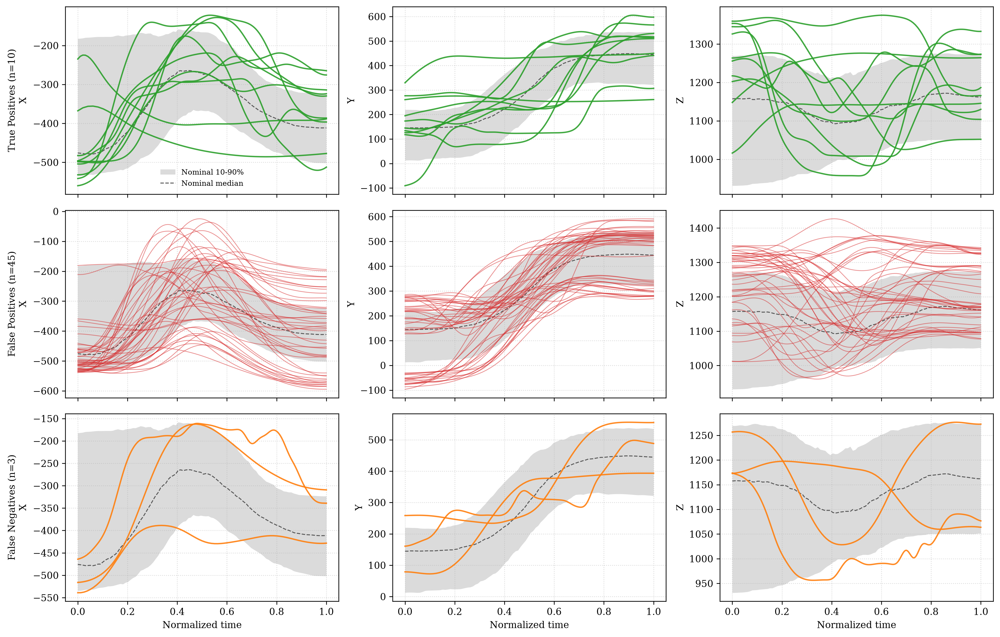

✅ Figura guardada em error_analysis_DBSCAN_FeatureBased_Pick.png


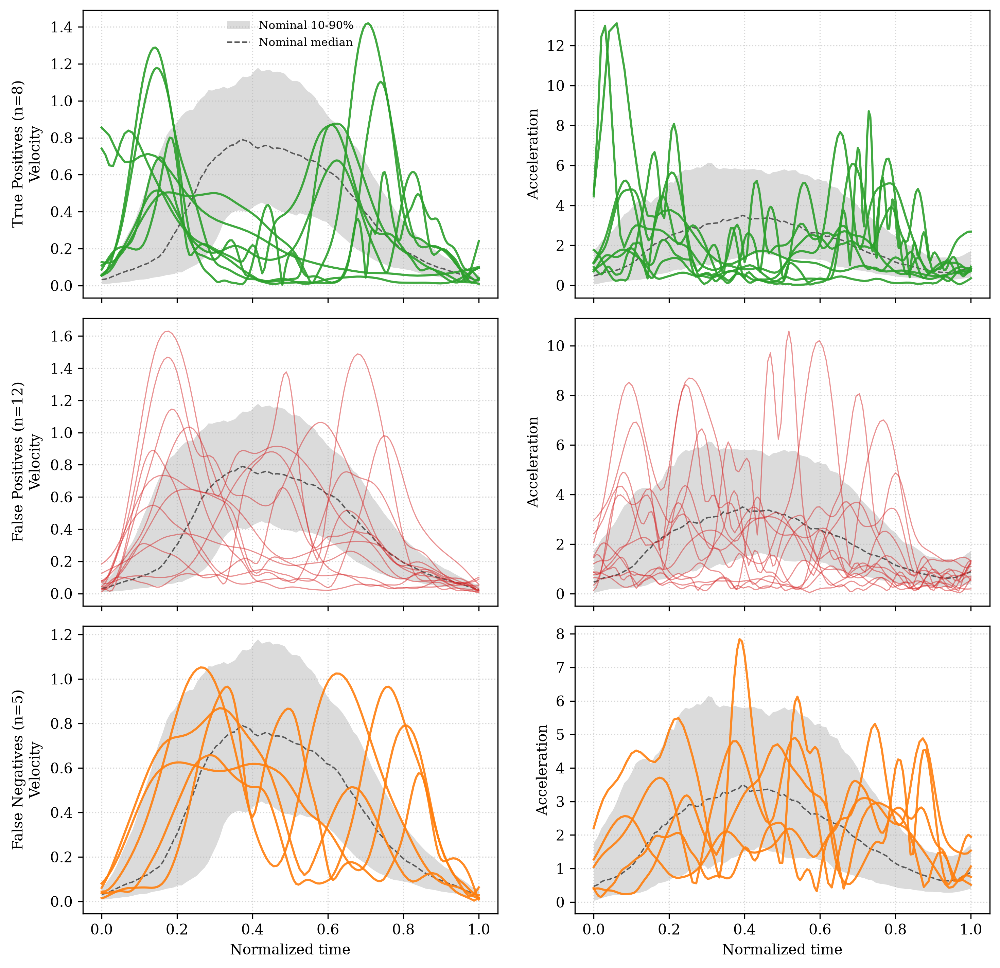

In [21]:
N_GRID = 100
T_GRID = np.linspace(0, 1, N_GRID)

# Ajustem as unidades de velocidade/aceleração às do dataset.
UNITS = {"x": "mm", "y": "mm", "z": "mm", "vel": "m/s", "acc": "m/s$^2$"}

def movement_series(raw_df, row, col):
    """Série temporal de um movimento, com tempo normalizado em [0, 1]."""
    m = raw_df[(raw_df["sub"] == row.sub) & (raw_df["repID"] == row.repID) &
               (raw_df["movID"] == row.movID)].sort_values("step")
    values = m[col].to_numpy()
    return np.linspace(0, 1, len(values)), values


def resampled_curves(raw_df, df_outcome, col):
    """Matriz (n_movimentos, N_GRID): cada curva reamostrada para a grelha comum."""
    curves = []
    for row in df_outcome.itertuples():
        t, v = movement_series(raw_df, row, col)
        curves.append(np.interp(T_GRID, t, v))
    return np.array(curves)


def plot_error_overlay(raw_df, outcomes, representation, categories=("TP", "FP", "FN"),
                       save_path=None):
    """
    Uma linha por categoria (TP/FP/FN), uma coluna por sinal.
    Em cada painel: banda nominal (mediana + percentis 10-90 de todos os TN)
    e as curvas individuais da categoria a cor.
    """
    signals = SIGNALS[representation]
    n_rows, n_cols = len(categories), len(signals)
    plt.rcParams.update({"font.size": 10, "font.family": "serif"})
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows),
                             dpi=300, squeeze=False, sharex=True)

    # Estilo por categoria: FP finos e transparentes, TP/FN mais fortes
    line_style = {
        "TP": dict(linewidth=1.5, alpha=0.9),
        "FP": dict(linewidth=0.8, alpha=0.5),
        "FN": dict(linewidth=1.5, alpha=0.9),
    }

    for c, (col, label) in enumerate(signals):
        # A banda nominal é igual em todas as linhas desta coluna: calcula-se uma vez
        tn = resampled_curves(raw_df, outcomes["TN"], col)
        lo, med, hi = np.percentile(tn, [10, 50, 90], axis=0)

        for r, cat in enumerate(categories):
            ax = axes[r][c]
            style = CATEGORY_STYLE[cat]

            ax.fill_between(T_GRID, lo, hi, color="0.6", alpha=0.35, linewidth=0,
                            label="Nominal 10-90%", zorder=1)
            ax.plot(T_GRID, med, color="0.35", linewidth=1.0, linestyle="--",
                    label="Nominal median", zorder=2)

            rows = list(outcomes[cat].sort_values(["sub", "repID", "movID"]).itertuples())
            for row in rows:
                t, v = movement_series(raw_df, row, col)
                ax.plot(t, v, color=style["color"], zorder=3, **line_style[cat])

            ax.grid(True, linestyle=":", alpha=0.5)
            if r == n_rows - 1:
                ax.set_xlabel("Normalized time")
            if c == 0:
                ax.set_ylabel(f"{style['title']} (n={len(rows)})\n{label}")
            else:
                ax.set_ylabel(label)

    # Legenda uma só vez, no painel do canto superior esquerdo
    axes[0][0].legend(loc="best", fontsize=8, frameon=False)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
        print(f"✅ Figura guardada em {save_path}")
    plt.show()


for representation in SIGNALS:
    oof = load_oof(MODEL, representation, TARGET_MOVEMENT)
    outcomes = split_outcomes(oof)
    plot_error_overlay(raw_df, outcomes, representation,
                       save_path=f"error_analysis_{MODEL}_{representation}_{TARGET_MOVEMENT}.png")